# 02. 위치 매핑과 데이터 품질
**목적**: 와이파이 AP그룹·버스 정류소를 행정동(읍면동 43개) 단위로 묶어 유동인구와 같은 단위에서 비교한다.

**방법** (`app/store/geo.py`, `app/store/cache.py`)
1. 주소 문자열에서 행정동 이름을 찾는다 (예: `서귀포시 성산읍 성산리` → `서귀포시 성산읍`)
2. 법정동만 있는 주소(예: `일도일동`)는 추측하지 않고, 주소로 확정된 **가장 가까운 정류소의 행정동**(2km 이내)을 쓴다
3. 둘 다 실패하면 버리지 않고 '매칭 실패'로 따로 센다

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
pd.set_option("display.max_colwidth", 60)
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False

In [2]:
from app.store.cache import CacheStore
st = CacheStore("data/cache")
s = st.stations
pd.DataFrame({"구분": ["주소로 매칭", "가까운 정류소로 매칭", "매칭 실패(제주 밖·2km 초과)"],
              "정류소 수": [(s["method"] == "address").sum(), (s["method"] == "nearest").sum(), st._station_unmatched]})

,구분,정류소 수
0,주소로 매칭,3665
1,가까운 정류소로 매칭,621
2,매칭 실패(제주 밖·2km 초과),66


AP그룹 1470개 매핑, 매칭 실패 그룹 11개, 정류소 행정동 41개 · AP그룹 행정동 42개 (전체 43개)


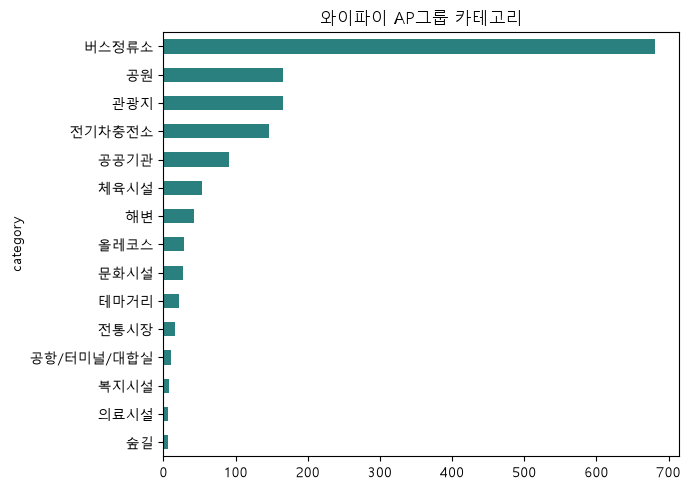

In [3]:
g = st.ap_groups
print(f"AP그룹 {len(g)}개 매핑, 매칭 실패 그룹 {len(st._ap_unmatched_groups)}개, 정류소 행정동 {s['emd'].nunique()}개 · AP그룹 행정동 {g['emd'].nunique()}개 (전체 43개)")
ax = g["category"].value_counts().plot.barh(figsize=(7, 5), color="#2A7F7F", title="와이파이 AP그룹 카테고리")
ax.invert_yaxis(); plt.tight_layout()

## 행정동별 커버리지 — 정류소·AP그룹 수, 가장 가까운 기상관측소

In [4]:
from app.store.geo import EMD_43
cov = pd.DataFrame({"행정동": EMD_43})
cov["정류소"] = cov["행정동"].map(s["emd"].value_counts()).fillna(0).astype(int)
cov["AP그룹"] = cov["행정동"].map(g["emd"].value_counts()).fillna(0).astype(int)
cov["관광지 AP그룹"] = cov["행정동"].map(g[g["category"] == "관광지"]["emd"].value_counts()).fillna(0).astype(int)
cov["기상관측소"] = cov["행정동"].map(st.station_of_emd)
cov

,행정동,정류소,AP그룹,관광지 AP그룹,기상관측소
0,제주시 한림읍,245,51,7,한림
1,제주시 애월읍,396,88,10,유수암
2,제주시 구좌읍,237,87,9,송당
3,제주시 조천읍,328,65,14,대흘
4,제주시 한경면,217,35,15,고산
5,제주시 추자면,0,0,0,NaN
6,제주시 우도면,0,20,9,NaN
7,제주시 일도1동,9,13,0,제주
8,제주시 일도2동,44,37,0,제주
9,제주시 이도1동,18,22,1,제주


**해석**: 정류소나 AP그룹이 0인 행정동은 해당 신호로 이상을 볼 수 없다 → 화면과 브리핑에 '신호 없음'으로 표시한다.